# kMC: validación con MONTY (Boerrigter et al. 2004)

Tercer notebook del proyecto. Comprueba que `kmc3d` reproduce los resultados de MONTY
(S. X. M. Boerrigter et al., *J. Phys. Chem. A* **108**, 5894 (2004);
`references/papers/MONTY2004/`). MONTY se validó con las curvas de **fracción de
adhesión** S(Δμ) por cara (ec. 22) de tres grasas: β-16.16.16 (Fig. 2), β′-10.12.10
(Fig. 3) y β′-16.16.14 (Fig. 4). El plan está en `PLAN_3DkMC.md` (§ «Validación con
MONTY»).

MONTY no simula un cristal finito sino **una superficie (hkl) con contorno periódico**,
y las grasas tienen **varias moléculas por celda**. Para compararse hacen falta dos
piezas nuevas, que no tocan nada de lo anterior (`KMC3D`, tasas, grafos y β-hematina
quedan igual):
- `kmc3d.basis_graph.BasisGraph`: grafo cristalino con Z unidades de crecimiento (GU)
  por celda, el formato de MONTY;
- `kmc3d.slab.SlabKMC`: el motor de superficie (modo *slab*), con las tasas de MONTY
  (`MontyRates`).

| § | Contenido |
|---|---|
| 1 | Configuración |
| 2 | **Parte A. Metodología** (sin datos de grasas): tasas, equilibrio, simetría partícula-hueco, Kossel, superficie frente a cristal finito, supercelda, caras opuestas |
| 3 | **Parte B. Grasas**: referencia digitalizada de las Figs. 2–4, estado de los datos y comparación |
| 4 | Conclusiones y pendientes |

**Unidades.** En la parte A, energías y Δμ en kT y tiempo en 1/k0 (k0 = 1). En la
parte B, como en el artículo, Δμ en kcal/mol (Δμ/kT = Δμ/RT).

**Reglas.** Salvo que se diga otra cosa, todas las corridas usan las reglas STS de MONTY
(un hueco cerrado puede llenarse, `allow_enclosed=True`); ver §2.3.

**Aviso.** El grafo de β-hematina se usa aquí solo como **grafo de prueba** (energías
provisionales de `presets.beta_hematin`). Nada de este notebook es un resultado sobre
β-hematina.

## 1. Configuración

In [1]:
import pickle
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Raíz del repositorio: la carpeta que contiene kmc3d/ (funciona desde notebooks/ o la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kmc3d").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

from kmc3d import monty, presets, render, viz                               # noqa: E402
from kmc3d.basis_graph import R_KCAL, BasisBond, BasisGraph                 # noqa: E402
from kmc3d.geometry import Cell                                             # noqa: E402
from kmc3d.parallel import run_parallel                                     # noqa: E402
from kmc3d.rates import SplitRates                                          # noqa: E402
from kmc3d.slab import MontyRates, SlabKMC                                  # noqa: E402

# Figuras, tablas y caché de las corridas pesadas
OUT = ROOT / "outputs" / "03_validacion_monty"
CACHE = OUT / "cache"
GUARDAR = True
CACHE.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    # Guarda la figura en OUT si GUARDAR = True
    if GUARDAR:
        fig.savefig(OUT / f"{nombre}.png", dpi=150, bbox_inches="tight")


def en_cache(nombre, calcular):
    # Devuelve el resultado guardado en CACHE/<nombre>.pkl o lo calcula y lo guarda.
    # Borra el archivo para recalcular.
    f = CACHE / f"{nombre}.pkl"
    if f.exists():
        with open(f, "rb") as fh:
            return pickle.load(fh)
    t0 = time.perf_counter()
    r = calcular()
    with open(f, "wb") as fh:
        pickle.dump(r, fh)
    print(f"{nombre}: calculado en {time.perf_counter() - t0:.0f} s")
    return r


def barrido(nombre, tareas):
    # Corre en paralelo una lista de tareas de monty.sticking_point (con caché) y
    # devuelve (DataFrame sin mapas, lista de resultados completos)
    res = en_cache(nombre, lambda: run_parallel("kmc3d.monty:sticking_point", tareas))
    return monty.results_frame(res), res


# Paleta categórica fija (orden estable), marcadores y estilo de las figuras
COLORES = render.FACE_PALETTE
MARCAS = viz.MARKERS
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
T0_NOTEBOOK = time.perf_counter()

## 2. Parte A: metodología

### 2.1 Correspondencia MONTY ↔ kmc3d

Las probabilidades de MONTY (ecs. 11 y 12), con U_moth = 0 y ΔV = 0, se escriben con
x = E − E_cr (energía de enlace del sitio menos la de red por GU, que es la del kink):

  k+ = exp[(1 − λ2)·Δμ + λ1·x],   k− = exp[−λ2·Δμ − (1 − λ1)·x].

Es la familia `SplitRates(a_mu, b_E)` que ya tenía el proyecto, con **a_mu = 1 − λ2 y
b_E = λ1**. El texto del artículo lo confirma: con λ1 = 0 la unión no depende del sitio,
con λ1 = 1 el despegue no depende del sitio, y λ1 = λ2 = 0 es la «lluvia aleatoria» de
Gilmer. MONTY usa λ1 = λ2 = ½ en las grasas, que es `SplitRates.symmetric`.

| MONTY | kmc3d |
|---|---|
| U^cryst, energía de red por GU | E_cr = Σ_b φ_b / Z (`BasisGraph.lattice_energy`) |
| U_moth ≠ 0 (ec. 8) | equivale a multiplicar todas las φ por 1 − U_moth/U^cryst (`BasisGraph.scaled`) |
| STS: unión con ≥ 1 enlace (también en un hueco cerrado: el texto admite inclusiones); no se despega una GU totalmente enlazada | `allow_enclosed=True`, el valor por defecto de `SlabKMC` (§2.3). `KMC3D` usa `False` (decisión D4) |
| Δt = τ/Q (ec. 16) | Δt = −ln u / W por defecto; `time_mode="media"` da la ec. 16. S no depende de t |
| S = (N_g − N_e)/N_g (ec. 22) | `SlabKMC.sticking_fraction()` tras `reset_counters()` |
| R_hkl = d_hkl (N_g − N_e)/(N_slice t) (ec. 20) | `SlabKMC.growth_rate()` |
| Celda de capa (u, v en el plano, w fuera) | `basis_graph.slice_cell`, reducida por Lagrange-Gauss |

La tabla siguiente compara, en todos los códigos de vecindad de β-hematina (grafo de
prueba), las tasas de `MontyRates(λ1, λ2)` con las de `SplitRates(1 − λ2, λ1)`.

In [2]:
g_bh = presets.beta_hematin()
filas = []
for l1, l2 in ((0.5, 0.5), (0.0, 0.0), (1.0, 0.0), (0.3, 0.8)):
    sr = SplitRates(g_bh, 1.3, a_mu=1 - l2, b_E=l1)
    mr = MontyRates(1.3, l1, l2)
    err_u = err_d = err_bd = 0.0
    for code in range(g_bh.full_code + 1):
        x = g_bh.code_energy(code) - g_bh.kink_energy
        err_u = max(err_u, abs(mr.attach(x) / sr.attach(code) - 1))
        err_d = max(err_d, abs(mr.detach(x) / sr.detach(code) - 1))
        # balance detallado: ln(k+/k−) = Δμ + x
        err_bd = max(err_bd, abs(np.log(mr.attach(x) / mr.detach(x)) - (1.3 + x)))
    filas.append({"λ1": l1, "λ2": l2, "a_mu": 1 - l2, "b_E": l1, "códigos": g_bh.full_code + 1,
                  "máx |k+ rel.|": err_u, "máx |k− rel.|": err_d, "máx error balance": err_bd})
pd.DataFrame(filas)

,λ1,λ2,a_mu,b_E,códigos,máx |k+ rel.|,máx |k− rel.|,máx error balance
0,0.5,0.5,0.5,0.5,2187,0.0,0.0,2.220e-16
1,0.0,0.0,1.0,0.0,2187,0.0,0.0,4.441e-16
2,1.0,0.0,1.0,1.0,2187,0.0,0.0,1.110e-16
3,0.3,0.8,0.2,0.3,2187,0.0,0.0,8.882e-16


### 2.2 Equilibrio: S(Δμ = 0) → 0

A Δμ = 0 la superficie no crece ni se disuelve en promedio, así que N_g − N_e no crece
con el número de eventos y S = (N_g − N_e)/N_g → 0. Cómo baja depende de la cara:
- en una cara **lisa**, N_g − N_e es la fluctuación del número de adátomos, que está
  acotada: S ∝ 1/N;
- en una cara **rugosa**, la altura media hace un paseo aleatorio: N_g − N_e ∝ √N y
  S ∝ 1/√N.

Kossel con φ = 3 kT (caras {100} lisas), caja de 40 × 40, 10 semillas por punto.

hkl,(001),(011),(111)
n_sample,,,
10000,8.482e-04,0.019,0.014
30000,3.184e-04,0.009,0.009
100000,9.550e-05,0.006,0.006
300000,4.462e-05,0.003,0.004


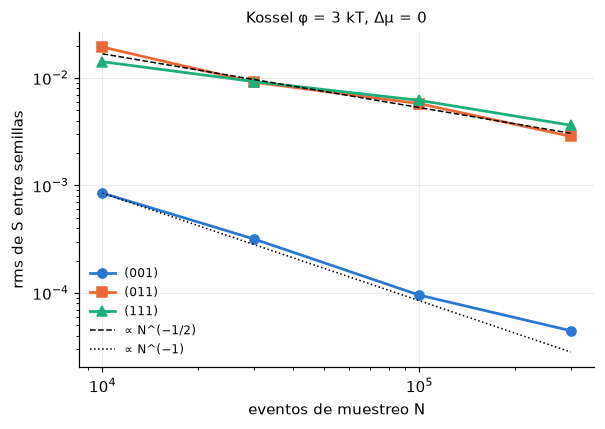

In [3]:
N_MUESTREO = [10_000, 30_000, 100_000, 300_000]
tareas = [{"graph": "kossel", "phi": 3.0, "hkl": f, "delta_mu": 0.0, "size": (40, 40),
           "n_equil": 50_000, "n_sample": n, "rng_seed": s, "keep_map": False}
          for f in ("(001)", "(011)", "(111)") for n in N_MUESTREO for s in range(1, 11)]
df_eq, _ = barrido("equilibrio", tareas)
rms = (df_eq.groupby(["hkl", "n_sample"])["S"].apply(lambda s: float(np.sqrt(np.mean(s ** 2))))
       .rename("rms(S)").reset_index())
display(rms.pivot(index="n_sample", columns="hkl", values="rms(S)"))

fig, ax = plt.subplots(figsize=(5.6, 4.0))
for i, (hkl, sub) in enumerate(rms.groupby("hkl")):
    ax.loglog(sub["n_sample"], sub["rms(S)"], marker=MARCAS[i], color=COLORES[i], lw=1.8, label=hkl)
# rectas de referencia que pasan por el primer punto de las caras rugosas y de la lisa
n = np.array(N_MUESTREO, float)
r0 = rms[rms["n_sample"] == n[0]].set_index("hkl")["rms(S)"]
ax.loglog(n, r0[["(011)", "(111)"]].mean() * (n / n[0]) ** -0.5, "k--", lw=1, label="∝ N^(−1/2)")
ax.loglog(n, r0["(001)"] * (n / n[0]) ** -1.0, "k:", lw=1, label="∝ N^(−1)")
ax.set_xlabel("eventos de muestreo N")
ax.set_ylabel("rms de S entre semillas")
ax.set_title("Kossel φ = 3 kT, Δμ = 0", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "equilibrio_S_vs_N")
plt.show()

### 2.3 Simetría partícula-hueco: crecer (hkl) = disolver (−h−k−l)

Con λ1 = λ2 = ½, y si todas las subredes tienen la misma energía total E_full = 2·E_cr
(se cumple siempre que todas las GU sean equivalentes por simetría), el cambio
n → 1 − n (ocupado ↔ vacío) transforma:
- la energía de enlace de un sitio, E → E_full − E, así que x = E − E_cr → −x;
- una unión a Δμ en un despegue a −Δμ con la misma tasa: e^{(Δμ + x)/2} = e^{−(−Δμ)/2 − (−x)/2};
- las dos reglas STS de MONTY una en otra: «no se une una GU sin ningún enlace» ↔ «no
  se despega una GU con todos los enlaces».

El cristal, que estaba debajo de la superficie (hkl), pasa a estar encima: es la cara
(−h−k−l). Por tanto, la dinámica de crecimiento de (hkl) a +Δμ es la misma, en
distribución y evento a evento, que la de disolución de (−h−k−l) a −Δμ:
R_(hkl)(Δμ) = −R_(−h−k−l)(−Δμ), con N_g y N_e intercambiados. Es lo que dice MONTY
con «para mantener el equilibrio en Δμ = 0, también se prohíbe despegar una GU
totalmente enlazada» (§2.3 del artículo): con las dos reglas, Δμ = 0 es exactamente la
coexistencia.

Consecuencias:
- es una **prueba exacta de todo el motor**: tasas, reglas, códigos de vecindad,
  contorno periódico y caja que crece por arriba (crecimiento) y por abajo (disolución);
- `allow_enclosed=False` (la regla de `KMC3D`, decisión D4: un hueco cerrado no se
  llena) no tiene pareja: su imagen sería «una GU sin enlaces no se despega». Rompe la
  simetría. El texto de MONTY admite inclusiones y no prohíbe llenarlas, así que sus
  reglas corresponden a `allow_enclosed=True`. Es lo que usa `SlabKMC` por defecto
  (decisión del autor, 2026-11-24); `KMC3D` sigue con `False`;
- con Gilmer (λ1 = λ2 = 0) la unión no depende del sitio y el despegue sí: no hay
  simetría.

Se prueba con Kossel (φ = 3 kT; (001) y (111) son centrosimétricas, así que la cara
opuesta es la misma) y con un cristal **P1 polar** de dos GU distintas, A y B, sin
inversión. Las capas A tienen enlaces laterales isótropos y las B muy anisótropos, pero
las dos subredes suman la misma energía total. 6 semillas (Kossel) y 8 (P1) por punto.

Energía total por subred (kT): [12.5, 12.5] ; E_cr = 6.25


,hkl,d_hkl,z0,n_slice,E_slice,E_att,E_cut,R_att_rel
0,(001),11.786,0.65,2,5.75,-0.5,1.0,1.0
1,(00-1),11.786,0.35,2,5.75,-0.5,1.0,1.0


puntos  max_abs_z  max_desv_rel
caso         regla                                                                    
Kossel φ = 3 Gilmer (λ = 0)                                10    469.550       247.482
             MONTY (λ = ½, huecos cerrados se llenan)      10      3.672         1.222
             λ = ½, huecos cerrados no se llenan           10      2.715         0.357
P1 polar     MONTY (λ = ½, huecos cerrados se llenan)       8      0.992         0.419
             λ = ½, huecos cerrados no se llenan            8     11.858         0.338

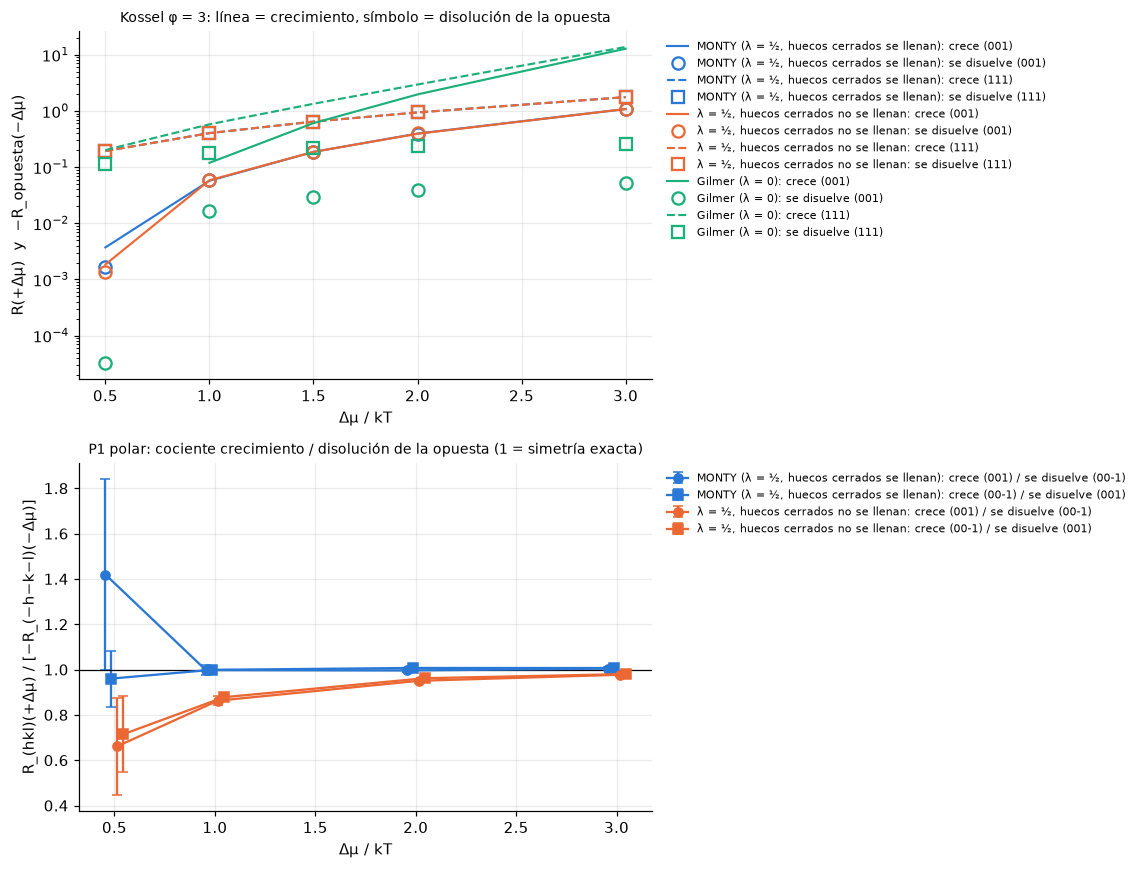

,caso,regla,cara,opuesta,Δμ,R(+Δμ),−R_opuesta(−Δμ),cociente,z,Ng/Ne (+Δμ),Ne/Ng opuesta (−Δμ)
10,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(001),(001),0.5,0.004,0.002,2.222,1.811,1.032,1.015
11,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(001),(001),1.0,0.057,0.058,0.979,-0.523,1.392,1.398
12,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(001),(001),1.5,0.187,0.188,0.990,-0.907,2.142,2.150
13,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(001),(001),2.0,0.396,0.395,1.001,0.170,3.399,3.398
14,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(001),(001),3.0,1.081,1.079,1.002,0.225,8.918,8.866
15,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(111),(111),0.5,0.193,0.193,1.002,0.321,1.589,1.587
16,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(111),(111),1.0,0.403,0.402,1.002,0.679,2.524,2.518
17,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(111),(111),1.5,0.646,0.645,1.001,0.527,4.008,3.994
18,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(111),(111),2.0,0.942,0.941,1.001,0.570,6.384,6.365
19,Kossel φ = 3,"MONTY (λ = ½, huecos cerrados se llenan)",(111),(111),3.0,1.762,1.766,0.998,-3.672,16.144,16.294


In [4]:
cell_j = Cell(10.0, 11.0, 12.0, 95.0, 100.0, 85.0)   # celda triclínica de juguete (Å)
# P1 polar: A en el origen, B desplazada; A–B fuerte dentro de la celda, B–A' débil.
# Laterales de A isótropos (2 + 2) y de B anisótropos (3.5 + 0.5): misma energía total.
g_p1 = BasisGraph(cell_j, [[0, 0, 0], [0.05, 0.1, 0.3]],
                  [BasisBond(0, 1, (0, 0, 0), 3.5, "A-B"), BasisBond(1, 0, (0, 0, 1), 1.0, "B-A'"),
                   BasisBond(0, 0, (1, 0, 0), 2.0, "A-A [100]"), BasisBond(0, 0, (0, 1, 0), 2.0, "A-A [010]"),
                   BasisBond(1, 1, (1, 0, 0), 3.5, "B-B [100]"), BasisBond(1, 1, (0, 1, 0), 0.5, "B-B [010]")],
                  units="kT", name="P1 polar")
print("Energía total por subred (kT):", [g_p1.full_energy(s) for s in range(g_p1.n_basis)],
      f"; E_cr = {g_p1.lattice_energy}")
display(g_p1.face_table([(0, 0, 1), (0, 0, -1)]))

# reglas: (λ1, λ2, allow_enclosed)
REGLAS = {"MONTY (λ = ½, huecos cerrados se llenan)": (0.5, 0.5, True),
          "λ = ½, huecos cerrados no se llenan": (0.5, 0.5, False),
          "Gilmer (λ = 0)": (0.0, 0.0, True)}
# caso: (parámetros, cara -> cara opuesta, Δμ > 0, semillas, reglas)
CASOS_PH = {"Kossel φ = 3": ({"graph": "kossel", "phi": 3.0, "size": (40, 40), "n_equil": 50_000,
                              "n_sample": 150_000}, {"(001)": "(001)", "(111)": "(111)"},
                             [0.5, 1.0, 1.5, 2.0, 3.0], range(1, 7), list(REGLAS)),
            "P1 polar": ({"graph": g_p1.to_dict(), "size": (30, 30), "n_equil": 60_000, "n_sample": 200_000},
                         {"(001)": "(00-1)", "(00-1)": "(001)"}, [0.5, 1.0, 2.0, 3.0], range(1, 9),
                         list(REGLAS)[:2])}
tareas = []
for caso, (base, opuesta, dmus, semillas, reglas) in CASOS_PH.items():
    for regla in reglas:
        l1, l2, ae = REGLAS[regla]
        for cara in opuesta:
            for d in dmus:
                for signo in (1, -1):
                    for s in semillas:
                        tareas.append({**base, "hkl": cara, "delta_mu": signo * d, "lambda1": l1, "lambda2": l2,
                                       "allow_enclosed": ae, "regla": regla, "caso": caso, "rng_seed": s,
                                       "keep_map": False})
df_ph, _ = barrido("particula_hueco", tareas)

# R(+Δμ) de cada cara frente a −R(−Δμ) de la cara opuesta
m = df_ph.groupby(["caso", "regla", "hkl", "delta_mu"]).agg(
    R=("R", "mean"), sem=("R", lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    Ng=("n_growth", "mean"), Ne=("n_etch", "mean"), S=("S", "mean")).reset_index()
filas = []
for (caso, regla, cara), sub in m[m["delta_mu"] > 0].groupby(["caso", "regla", "hkl"], sort=False):
    opp = CASOS_PH[caso][1][cara]
    for _, r in sub.iterrows():
        q = m[(m["caso"] == caso) & (m["regla"] == regla) & (m["hkl"] == opp)
              & np.isclose(m["delta_mu"], -r["delta_mu"])].iloc[0]
        filas.append({"caso": caso, "regla": regla, "cara": cara, "opuesta": opp, "Δμ": r["delta_mu"],
                      "R(+Δμ)": r["R"], "−R_opuesta(−Δμ)": -q["R"], "cociente": r["R"] / -q["R"],
                      "z": (r["R"] + q["R"]) / np.hypot(r["sem"], q["sem"]),
                      "Ng/Ne (+Δμ)": r["Ng"] / r["Ne"], "Ne/Ng opuesta (−Δμ)": q["Ne"] / q["Ng"]})
tab_ph = pd.DataFrame(filas)
resumen_ph = tab_ph.groupby(["caso", "regla"], sort=False).agg(
    puntos=("z", "size"), max_abs_z=("z", lambda z: float(np.abs(z).max())),
    max_desv_rel=("cociente", lambda c: float(np.abs(c - 1).max())))
display(resumen_ph)

# Kossel: línea = crecimiento de (hkl) a +Δμ; símbolo hueco = −R de la opuesta a −Δμ (disolución).
# P1 polar: cociente de las dos, en escala lineal, para que se vea la diferencia entre reglas.
fig, axes = plt.subplots(2, 1, figsize=(10.5, 8.0))
sub = tab_ph[tab_ph["caso"] == "P1 polar"]
ax = axes[1]
for i, regla in enumerate(CASOS_PH["P1 polar"][4]):
    for j, cara in enumerate(CASOS_PH["P1 polar"][1]):
        d = sub[(sub["regla"] == regla) & (sub["cara"] == cara)]
        # error del cociente: (R+ − (−R−)) / z es el error combinado de la diferencia
        err = np.abs((d["R(+Δμ)"] - d["−R_opuesta(−Δμ)"]) / d["z"]) / d["−R_opuesta(−Δμ)"]
        ax.errorbar(d["Δμ"] + 0.03 * (2 * i + j - 1.5), d["cociente"], yerr=err, fmt=MARCAS[j] + "-",
                    color=COLORES[i], ms=6, capsize=3, label=f"{regla}: crece {cara} / se disuelve "
                    f"{CASOS_PH['P1 polar'][1][cara]}")
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("Δμ / kT")
ax.set_ylabel("R_(hkl)(+Δμ) / [−R_(−h−k−l)(−Δμ)]")
ax.set_title("P1 polar: cociente crecimiento / disolución de la opuesta (1 = simetría exacta)", fontsize=9)
ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
for ax, caso in zip(axes[:1], ["Kossel φ = 3"]):
    sub = tab_ph[tab_ph["caso"] == caso]
    for i, regla in enumerate(CASOS_PH[caso][4]):
        for j, cara in enumerate(CASOS_PH[caso][1]):
            d = sub[(sub["regla"] == regla) & (sub["cara"] == cara)]
            ax.plot(d["Δμ"], d["R(+Δμ)"].where(d["R(+Δμ)"] > 0), color=COLORES[i], lw=1.4,
                    ls="-" if j == 0 else "--", label=f"{regla}: crece {cara}")
            ax.plot(d["Δμ"], d["−R_opuesta(−Δμ)"].where(d["−R_opuesta(−Δμ)"] > 0), MARCAS[j], color=COLORES[i],
                    mfc="none", ms=8, mew=1.5, label=f"{regla}: se disuelve {CASOS_PH[caso][1][cara]}")
    ax.set_yscale("log")
    ax.set_xlabel("Δμ / kT")
    ax.set_ylabel("R(+Δμ)  y  −R_opuesta(−Δμ)")
    ax.set_title(f"{caso}: línea = crecimiento, símbolo = disolución de la opuesta", fontsize=9)
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
guardar(fig, "particula_hueco")
plt.show()
tab_ph[tab_ph["regla"] != "Gilmer (λ = 0)"].round(3)

**Efecto de la regla de los huecos cerrados en las curvas S(Δμ).** Misma corrida, solo
la parte de crecimiento (Δμ > 0).

In [5]:
efecto = (m[(m["delta_mu"] > 0) & (m["regla"] != "Gilmer (λ = 0)")]
          .pivot_table(index=["caso", "hkl", "delta_mu"], columns="regla", values="S"))
efecto["diferencia"] = efecto[list(REGLAS)[1]] - efecto[list(REGLAS)[0]]
efecto.round(4)

regla                         MONTY (λ = ½, huecos cerrados se llenan)  λ = ½, huecos cerrados no se llenan  diferencia
caso         hkl    delta_mu                                                                                           
Kossel φ = 3 (001)  0.5                                          0.031                                0.016  -1.480e-02
                    1.0                                          0.281                                0.285   3.300e-03
                    1.5                                          0.533                                0.533   3.000e-04
                    2.0                                          0.706                                0.705  -1.000e-03
                    3.0                                          0.888                                0.888  -1.000e-04
             (111)  0.5                                          0.371                                0.370  -7.000e-04
                    1.0                                          0.604                                0.603  -8.000e-04
                    1.5                                          0.750                                0.750  -4.000e-04
                    2.0                                          0.843                                0.843  -8.000e-04
                    3.0                                          0.938                                0.939   5.000e-04
P1 polar     (00-1) 0.5                                          0.045                                0.044  -5.000e-04
                    1.0                                          0.369                                0.328  -4.170e-02
                    2.0                                          0.769                                0.633  -1.360e-01
                    3.0                                          0.916                                0.805  -1.108e-01
             (001)  0.5                                          0.030                                0.028  -2.900e-03
                    1.0                                          0.334                                0.317  -1.710e-02
                    2.0                                          0.754                                0.659  -9.530e-02
                    3.0                                          0.912                                0.836  -7.580e-02

### 2.4 Kossel: curvas S(Δμ) por cara

Kossel (6 vecinos, misma φ) con el protocolo de MONTY para β-16.16.16: caja de 40 × 40,
10⁵ eventos de equilibrado y 10⁵ de muestreo, λ1 = λ2 = ½, 3 semillas. Lo esperado,
según la teoría de caras F/S/K de Hartman-Perdok (y lo que dice MONTY de sus grasas):
- (001) es una cara F: tiene un umbral de nucleación 2D que sube con φ;
- (011) es S y (111) es K: crecen desde Δμ = 0 (S > 0 en cuanto Δμ > 0).

Referencia para las caras rugosas: si todas las uniones y despegues fueran en
posiciones de kink (x = 0), k−/k+ = e^{−Δμ} y S = 1 − e^{−Δμ} (línea gris
discontinua; S = ½ en Δμ = ln 2 ≈ 0.69). Los adátomos que se unen y se van sin crecer
suman a N_g y a N_e por igual y bajan S, así que las caras rugosas quedan algo por
debajo de esa curva.

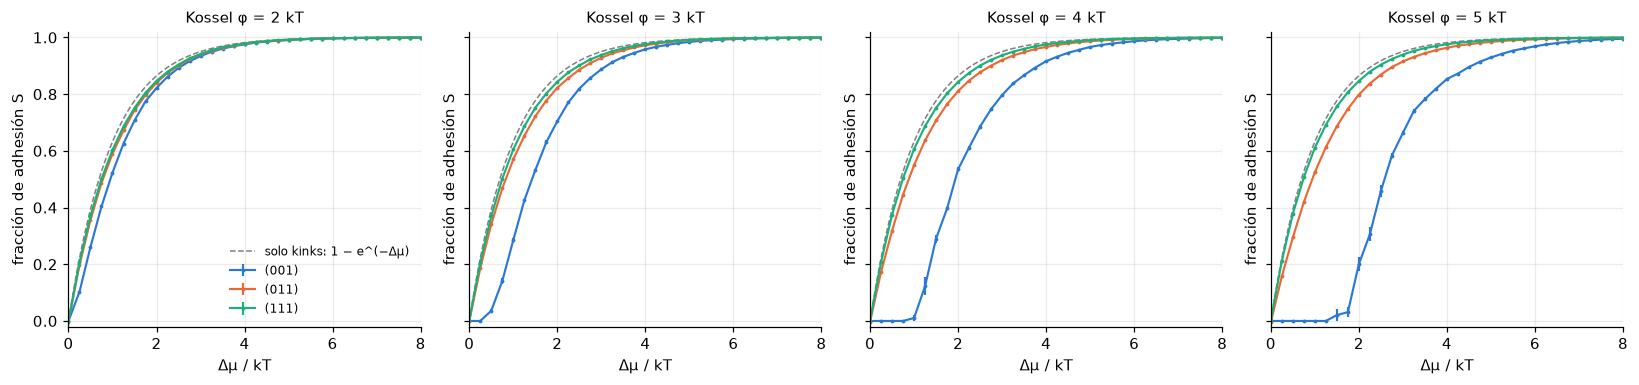

delta_mu@S=0.1  delta_mu@S=0.5  delta_mu@S=0.9
phi hkl                                                  
2.0 (001)           0.243           0.952           2.579
    (011)           0.127           0.783           2.492
    (111)           0.122           0.749           2.456
3.0 (001)           0.652           1.426           3.122
    (011)           0.135           0.829           2.647
    (111)           0.120           0.747           2.489
4.0 (001)           1.199           1.937           3.823
    (011)           0.147           0.880           2.744
    (111)           0.120           0.743           2.491
5.0 (001)           1.852           2.583           4.558
    (011)           0.161           0.942           2.808
    (111)           0.116           0.737           2.458

In [6]:
PHIS = [2.0, 3.0, 4.0, 5.0]
CARAS_K = ["(001)", "(011)", "(111)"]
DMU_K = np.round(np.arange(0.0, 8.01, 0.25), 3)
base_k = {"graph": "kossel", "size": (40, 40), "n_equil": 100_000, "n_sample": 100_000, "keep_map": False}
tareas = [t for phi in PHIS
          for t in monty.sticking_grid({**base_k, "phi": phi}, CARAS_K, delta_mu=DMU_K, seeds=(1, 2, 3))]
df_k, _ = barrido("kossel_curvas", tareas)

fig, axes = plt.subplots(1, len(PHIS), figsize=(15, 3.6), sharey=True)
for ax, phi in zip(axes, PHIS):
    sub = df_k[df_k["phi"] == phi]
    for i, cara in enumerate(CARAS_K):
        monty.plot_sticking(sub, ax=ax, faces=[cara], color=COLORES[i])
    xx = np.linspace(0, 8, 200)
    ax.plot(xx, 1 - np.exp(-xx), color="0.5", ls="--", lw=1, label="solo kinks: 1 − e^(−Δμ)")
    ax.set_title(f"Kossel φ = {phi:g} kT", fontsize=10)
    ax.set_xlim(0, 8)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "kossel_S_vs_dmu")
plt.show()

umbrales_k = pd.concat([monty.onset_table(df_k[df_k["phi"] == phi]).assign(phi=phi) for phi in PHIS])
umbrales_k.set_index(["phi", "hkl"])

**Mapas de alturas** de la cara (001) con φ = 4 kT al final del muestreo, por debajo,
cerca y por encima del umbral: islas aisladas que no llegan al tamaño crítico, nucleación
2D y crecimiento rugoso.

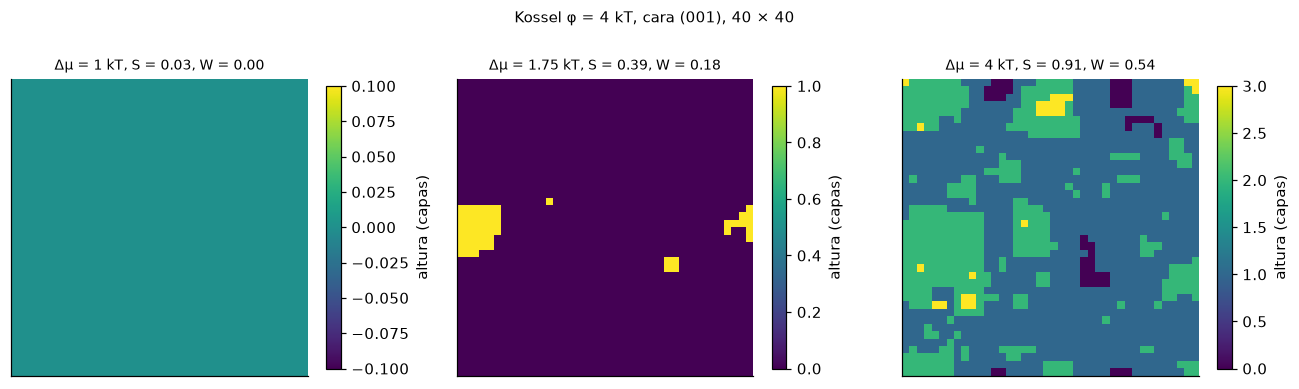

In [7]:
tareas = [{"graph": "kossel", "phi": 4.0, "hkl": "(001)", "delta_mu": d, "size": (40, 40),
           "n_equil": 100_000, "n_sample": 100_000, "rng_seed": 1} for d in (1.0, 1.75, 4.0)]
_, res_mapas = barrido("kossel_mapas", tareas)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, r in zip(axes, res_mapas):
    m = r["mapa"] - np.floor(r["mapa"].min())
    im = ax.imshow(m.T, origin="lower", cmap="viridis", interpolation="nearest")
    ax.set_title(f"Δμ = {r['delta_mu']:g} kT, S = {r['S']:.2f}, W = {r['W']:.2f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8, label="altura (capas)")
fig.suptitle("Kossel φ = 4 kT, cara (001), 40 × 40", fontsize=10)
fig.tight_layout()
guardar(fig, "kossel_mapas_001")
plt.show()

**Energía de borde efectiva** (semicuantitativo). MONTY dice que el umbral de las curvas
lo fija la energía libre de borde γ de la nucleación 2D (§2.6). En la cara (001) de
Kossel, la capa superior es un gas de red 2D cuadrado con interacción φ, es decir, un
modelo de Ising 2D con J = φ/4. Su energía libre de borde según un eje es exacta
(Onsager): γ/kT = φ/2kT + ln tanh(φ/4kT).

Con una isla cuadrada, la barrera de nucleación es ΔG* = 4γ²/Δμ. De ln R frente a 1/Δμ
en la zona de umbral (0.003 < S < 0.35) sale γ_eff, pero el resultado depende del
régimen:
- **mononuclear** (una isla completa la capa): ln R ≈ cte − 4γ²/Δμ;
- **birth-and-spread** (muchas islas por capa): ln R ≈ cte + (5/6) ln Δμ − 4γ²/(3Δμ).

En una caja de 40 × 40 y cerca del umbral no está claro cuál de los dos domina, así que
se dan las dos lecturas. La forma real del núcleo no es un cuadrado perfecto a T finita.
La comprobación es de orden de magnitud: el γ de Onsager debería caer entre las dos.

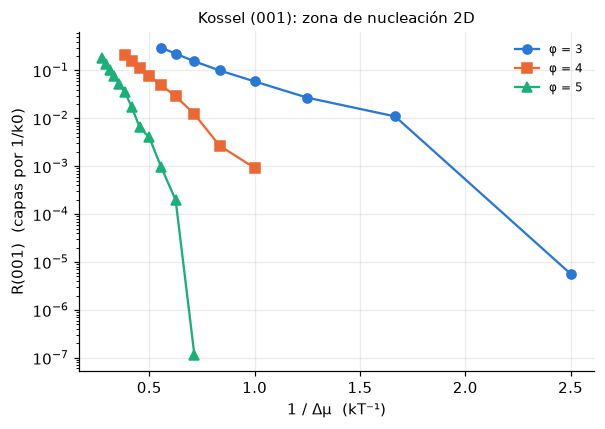

,φ (kT),puntos,γ Onsager,γ_eff mononuclear,γ_eff birth-and-spread,Onsager entre las dos
0,3.0,3,1.046,0.788,1.179,True
1,4.0,4,1.728,1.532,2.503,True
2,5.0,4,2.335,2.300,3.835,True


In [8]:
def gamma_onsager(phi):
    # Energía libre de borde (por sitio, en kT) de un gas de red cuadrado: Ising 2D con J = φ/4
    return phi / 2 + np.log(np.tanh(phi / 4))


VENTANAS = {3.0: np.arange(0.4, 1.81, 0.2), 4.0: np.arange(0.8, 2.61, 0.2), 5.0: np.arange(1.4, 3.61, 0.2)}
tareas = [t for phi, d in VENTANAS.items()
          for t in monty.sticking_grid({**base_k, "phi": phi, "n_sample": 300_000}, ["(001)"],
                                       delta_mu=np.round(d, 3), seeds=(1, 2))]
df_g, _ = barrido("kossel_gamma", tareas)
filas = []
fig, ax = plt.subplots(figsize=(5.6, 4.0))
for i, (phi, sub) in enumerate(df_g.groupby("phi")):
    m = sub.groupby("delta_mu")[["R", "S"]].mean().reset_index()
    ok = (m["S"] > 0.003) & (m["S"] < 0.35)
    x = 1 / m.loc[ok, "delta_mu"]
    p_mono = np.polyfit(x, np.log(m.loc[ok, "R"]), 1)[0]
    p_bys = np.polyfit(x, np.log(m.loc[ok, "R"] / m.loc[ok, "delta_mu"] ** (5 / 6)), 1)[0]
    filas.append({"φ (kT)": phi, "puntos": int(ok.sum()), "γ Onsager": gamma_onsager(phi),
                  "γ_eff mononuclear": np.sqrt(-p_mono / 4), "γ_eff birth-and-spread": np.sqrt(-3 * p_bys / 4)})
    ax.semilogy(1 / m["delta_mu"], m["R"].where(m["R"] > 0), marker=MARCAS[i], color=COLORES[i], lw=1.5,
                label=f"φ = {phi:g}")
ax.set_xlabel("1 / Δμ  (kT⁻¹)")
ax.set_ylabel("R(001)  (capas por 1/k0)")
ax.set_title("Kossel (001): zona de nucleación 2D", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "kossel_lnR_vs_inv_dmu")
plt.show()
tab_g = pd.DataFrame(filas)
tab_g["Onsager entre las dos"] = (tab_g["γ_eff mononuclear"] <= tab_g["γ Onsager"]) & \
                                 (tab_g["γ Onsager"] <= tab_g["γ_eff birth-and-spread"])
tab_g

### 2.5 Superficie frente a cristal finito

La velocidad de la cara (001) en el *slab* periódico (ec. 20) debe coincidir con la de
las caras {100} de un cristal finito de `KMC3D` (`experiments.kossel_face_growth`: cubo
semilla de 20³ que crece hasta 2·N0, plano medio del centro de cada cara). La diferencia
esperable: el cristal finito tiene aristas y un tamaño finito (Gibbs-Thomson), que
rebajan algo la fuerza impulsora efectiva, sobre todo a Δμ bajo. 3 semillas por punto.
Para comparar igual con igual, aquí el slab usa la regla de `KMC3D` (un hueco cerrado
no se llena); en el resto del notebook usa las de MONTY.

R_cristal  sd_cristal  R_slab    sd_slab      S  cristal / slab  err. cociente
rates     phi delta_mu                                                                                
gilmer    2.0 0.5           0.139       0.011   0.170  5.302e-03  0.098           0.822          0.071
              1.0           0.751       0.046   0.791  6.022e-03  0.250           0.949          0.058
              2.0           7.035       0.277   8.196  9.631e-02  0.545           0.858          0.035
          3.0 1.5           0.561       0.047   0.608  9.561e-03  0.133           0.922          0.079
              3.0          11.725       0.104  12.133  8.433e-02  0.467           0.966          0.011
symmetric 2.0 0.5           0.108       0.009   0.125  6.491e-03  0.244           0.864          0.088
              1.0           0.353       0.008   0.379  9.023e-04  0.506           0.931          0.022
              2.0           1.147       0.032   1.193  1.081e-02  0.798           0.962          0.028
          3.0 1.5           0.164       0.012   0.188  6.715e-03  0.536           0.869          0.072
              3.0           1.011       0.032   1.075  5.892e-03  0.887           0.941          0.030

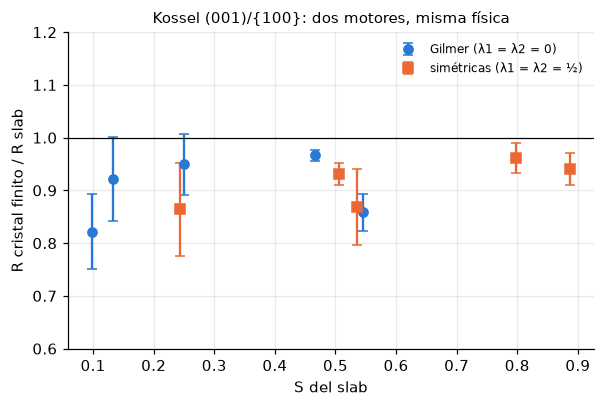

In [9]:
CASOS = [(2.0, 0.5), (2.0, 1.0), (2.0, 2.0), (3.0, 1.5), (3.0, 3.0)]
t_cr, t_sl = [], []
for rates in ("gilmer", "symmetric"):
    l1, l2 = (0.0, 0.0) if rates == "gilmer" else (0.5, 0.5)
    for phi, dmu in CASOS:
        for s in (1, 2, 3):
            t_cr.append({"phi": phi, "delta_mu": dmu, "rates": rates, "L": 20, "growth": 2.0, "rng_seed": s})
            t_sl.append({"graph": "kossel", "phi": phi, "delta_mu": dmu, "lambda1": l1, "lambda2": l2,
                         "rates": rates, "hkl": "(001)", "size": (40, 40), "n_equil": 50_000,
                         "n_sample": 150_000, "rng_seed": s, "keep_map": False,
                         "allow_enclosed": False})     # la regla de KMC3D, para comparar igual con igual
res_cr = en_cache("cristal_finito", lambda: run_parallel("kmc3d.experiments:kossel_face_growth", t_cr))
df_sl, _ = barrido("slab_vs_cristal", t_sl)
a = pd.DataFrame([{k: r[k] for k in ("phi", "delta_mu", "rates", "R")} for r in res_cr])
ga = a.groupby(["rates", "phi", "delta_mu"])["R"].agg(R_cristal="mean", sd_cristal="std")
gb = df_sl.groupby(["rates", "phi", "delta_mu"]).agg(R_slab=("R", "mean"), sd_slab=("R", "std"), S=("S", "mean"))
comp_cr = ga.join(gb)
comp_cr["cristal / slab"] = comp_cr["R_cristal"] / comp_cr["R_slab"]
comp_cr["err. cociente"] = comp_cr["cristal / slab"] * np.sqrt((comp_cr["sd_cristal"] / comp_cr["R_cristal"]) ** 2
                                                                + (comp_cr["sd_slab"] / comp_cr["R_slab"]) ** 2)
display(comp_cr)

fig, ax = plt.subplots(figsize=(5.6, 3.8))
for i, (rates, sub) in enumerate(comp_cr.reset_index().groupby("rates")):
    lab = {"gilmer": "Gilmer (λ1 = λ2 = 0)", "symmetric": "simétricas (λ1 = λ2 = ½)"}[rates]
    ax.errorbar(sub["S"], sub["cristal / slab"], yerr=sub["err. cociente"], fmt=MARCAS[i], color=COLORES[i],
                ms=6, capsize=3, label=lab)
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("S del slab")
ax.set_ylabel("R cristal finito / R slab")
ax.set_ylim(0.6, 1.2)
ax.legend(frameon=False, fontsize=8)
ax.set_title("Kossel (001)/{100}: dos motores, misma física", fontsize=10)
fig.tight_layout()
guardar(fig, "slab_vs_cristal_finito")
plt.show()

Si la diferencia es de tamaño finito, debe desaparecer al crecer el cristal. Se repite
el cristal finito con semillas de L = 12, 20, 32 y 48 (6 semillas) en los dos casos con
el cociente más bajo. No se extrapola: con S ≈ 0.1–0.5 la cara crece por nucleación 2D,
y en una cara pequeña la nucleación depende del área y de las aristas, así que R(L) no
tiene por qué ser lineal en 1/L (un ajuste lineal se pasa del valor del slab).

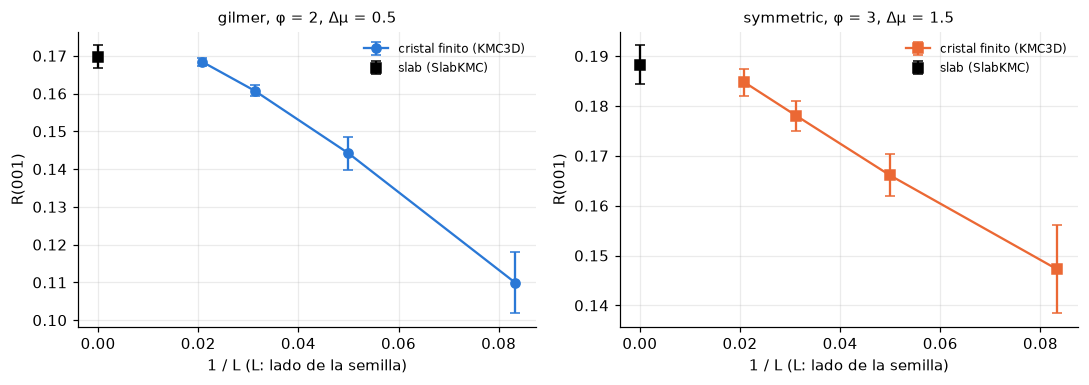

cristal / slab           error cociente          
tasas         gilmer symmetric         gilmer symmetric
L                                                      
12             0.647     0.782          0.049     0.049
20             0.849     0.882          0.030     0.029
32             0.947     0.945          0.019     0.025
48             0.992     0.981          0.019     0.025

In [10]:
TAM = [12, 20, 32, 48]
CASOS_L = [("gilmer", 2.0, 0.5), ("symmetric", 3.0, 1.5)]
t_L = [{"phi": phi, "delta_mu": dmu, "rates": rates, "L": L, "growth": 2.0, "rng_seed": s}
       for rates, phi, dmu in CASOS_L for L in TAM for s in range(1, 7)]


def correr_L():
    # sin las coordenadas finales, que ocupan mucho en la caché
    res = run_parallel("kmc3d.experiments:kossel_face_growth", t_L)
    return [{k: v for k, v in r.items() if k != "coords"} for r in res]


df_L = pd.DataFrame(en_cache("cristal_finito_L", correr_L))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
filas = []
for ax, (i, (rates, phi, dmu)) in zip(axes, enumerate(CASOS_L)):
    d = df_L[df_L["rates"] == rates].groupby("L")["R"].agg(["mean", "std", "count"]).reset_index()
    d["sem"] = d["std"] / np.sqrt(d["count"])
    r_slab = comp_cr.loc[(rates, phi, dmu), "R_slab"]
    e_slab = comp_cr.loc[(rates, phi, dmu), "sd_slab"] / np.sqrt(3)      # 3 semillas del slab
    for _, r in d.iterrows():
        filas.append({"tasas": rates, "φ": phi, "Δμ": dmu, "L": int(r["L"]), "R cristal": r["mean"],
                      "error": r["sem"], "R slab": r_slab, "cristal / slab": r["mean"] / r_slab,
                      "error cociente": r["mean"] / r_slab * np.hypot(r["sem"] / r["mean"], e_slab / r_slab)})
    ax.errorbar(1 / d["L"], d["mean"], yerr=d["sem"], fmt=MARCAS[i] + "-", color=COLORES[i], ms=6, capsize=3,
                label="cristal finito (KMC3D)")
    ax.errorbar([0], [r_slab], yerr=[e_slab], fmt="s", color="k", ms=6, capsize=3, label="slab (SlabKMC)")
    ax.set_xlabel("1 / L (L: lado de la semilla)")
    ax.set_ylabel("R(001)")
    ax.set_title(f"{rates}, φ = {phi:g}, Δμ = {dmu:g}", fontsize=10)
    ax.set_xlim(left=-0.004)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, "cristal_finito_vs_L")
plt.show()
pd.DataFrame(filas).pivot_table(index="L", columns="tasas", values=["cristal / slab", "error cociente"])

### 2.6 Invariancia de supercelda (base > 1)

Las grasas necesitan varias GU por celda. Una forma de comprobar el código de base > 1
sin datos externos es describir el **mismo** cristal con una celda mayor, con 2 GU en
vez de 1: las curvas S(Δμ) no deben cambiar. Los tests ya comprueban que la energía de
cada sitio coincide exactamente con la contada a mano (`tests/test_slab.py`). Aquí se
comprueba la estadística completa. La caja se elige con el mismo número de GU por capa
(1600) y lo más cuadrada posible.
- Kossel φ = 4 kT, caras (001) y (111), supercelda 2 × 1 × 1;
- β-hematina (grafo de prueba, energías provisionales), caras (100) y (011), supercelda
  1 × 2 × 1.

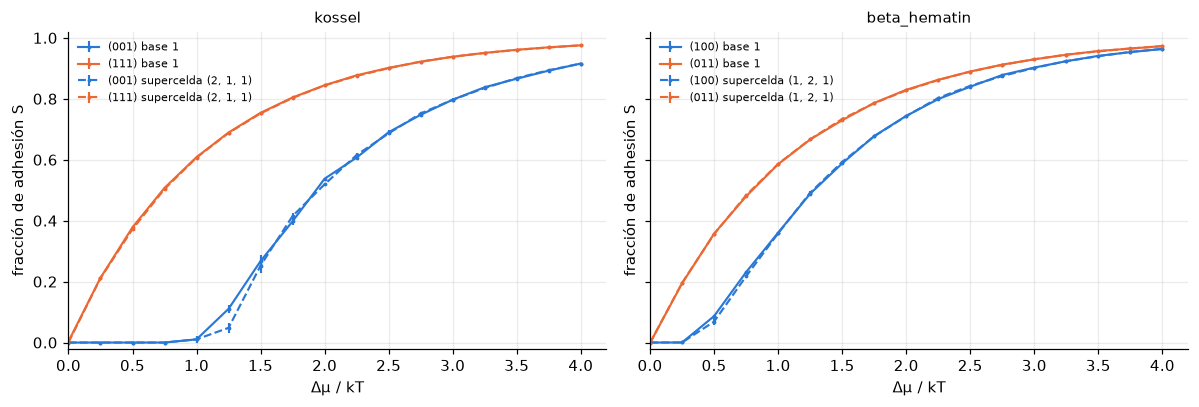

,caso,cara,descripcion,Z,caja,Δμ@S=0.1,Δμ@S=0.5,Δμ@S=0.9
0,kossel,(001),base 1,1,"(40, 40)",1.223,1.932,3.830
1,kossel,(111),base 1,1,"(40, 40)",0.115,0.735,2.484
2,kossel,(001),"supercelda (2, 1, 1)",2,"(40, 20)",1.313,1.953,3.821
3,kossel,(111),"supercelda (2, 1, 1)",2,"(37, 22)",0.118,0.743,2.495
4,beta_hematin,(100),base 1,1,"(54, 30)",0.523,1.279,2.975
5,beta_hematin,(011),base 1,1,"(47, 34)",0.130,0.798,2.616
6,beta_hematin,(100),"supercelda (1, 2, 1)",2,"(54, 15)",0.552,1.271,2.987
7,beta_hematin,(011),"supercelda (1, 2, 1)",2,"(47, 17)",0.128,0.790,2.622


In [11]:
from kmc3d.basis_graph import slice_cell


def caja_equivalente(g, hkl, n_por_capa=1600):
    # (L1, L2) con L1·L2·Z ≈ n_por_capa y la caja física lo más cuadrada posible
    B = slice_cell(hkl, g.cell)
    lu, lv = (np.linalg.norm(B[k] @ g.cell.matrix) for k in (0, 1))
    celdas = n_por_capa / g.n_basis
    L1 = max(4, int(round(np.sqrt(celdas * lv / lu))))
    return (L1, max(4, int(round(celdas / L1))))


CASOS_SC = [("kossel", {"graph": "kossel", "phi": 4.0}, (2, 1, 1), [(0, 0, 1), (1, 1, 1)], np.arange(0, 4.01, 0.25)),
            ("beta_hematin", {"graph": "beta_hematin"}, (1, 2, 1), [(1, 0, 0), (0, 1, 1)], np.arange(0, 4.01, 0.25))]
tareas = []
for nombre, spec, sc, caras, dmus in CASOS_SC:
    g1 = monty.graph_from_params(spec)
    g2 = g1.supercell(*sc)
    for etiqueta, g, extra in (("base 1", g1, {}), (f"supercelda {sc}", g2, {"supercell": sc})):
        for cara in caras:
            # la misma cara en índices de la supercelda: (h·n1, k·n2, l·n3)
            hkl = tuple(x * (n if extra else 1) for x, n in zip(cara, sc))
            for d in np.round(dmus, 3):
                for s in (1, 2, 3):
                    tareas.append({**spec, **extra, "hkl": hkl, "cara": monty.hkl_label(cara), "caso": nombre,
                                   "descripcion": etiqueta, "Zc": g.n_basis, "delta_mu": float(d),
                                   "size": caja_equivalente(g, hkl), "n_equil": 50_000, "n_sample": 100_000,
                                   "rng_seed": s, "keep_map": False})
df_sc, _ = barrido("supercelda", tareas)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
filas = []
for ax, (nombre, *_r) in zip(axes, CASOS_SC):
    sub = df_sc[df_sc["caso"] == nombre]
    orden = list(dict.fromkeys(sub["cara"]))           # color por cara, trazo por descripción
    for (cara, desc), d in sub.groupby(["cara", "descripcion"], sort=False):
        d = d.assign(hkl=f"{cara} {desc}")
        monty.plot_sticking(d, ax=ax, color=COLORES[orden.index(cara)], ls="-" if desc == "base 1" else "--")
        on = monty.onset_table(d).iloc[0]
        filas.append({"caso": nombre, "cara": cara, "descripcion": desc, "Z": int(d["Zc"].iloc[0]),
                      "caja": d["size"].iloc[0], "Δμ@S=0.1": on["delta_mu@S=0.1"],
                      "Δμ@S=0.5": on["delta_mu@S=0.5"], "Δμ@S=0.9": on["delta_mu@S=0.9"]})
    ax.set_title(nombre, fontsize=10)
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
guardar(fig, "supercelda")
plt.show()
pd.DataFrame(filas)

### 2.7 Caras opuestas

En P-1, (hkl) y (−h−k−l) pertenecen a la misma forma y MONTY comprueba que sus curvas
coinciden (§3.2). Para probarlo con base > 1 se construye un cristal P-1 de juguete con
dos GU relacionadas por un centro de inversión (`BasisGraph.from_centers` con la
operación −x). Como control se usa el cristal P1 polar del §2.3, sin inversión. Las
dos corridas usan las reglas de MONTY.

Lo que cabe esperar del control, por el §2.3: con enlaces de par, (hkl) y (−h−k−l)
rompen los mismos enlaces (E_cut igual) y la simetría partícula-hueco hace iguales sus
energías libres de superficie y de borde en la coexistencia. Por eso, incluso en un
cristal polar, las curvas solo pueden separarse por la cinética a Δμ finito, no en el
umbral.

,enlace,i,j,shift,longitud,phi (kT)
0,dímero,M1,M1_op1,"(-1, -1, -1)",8.477,4.50
1,b2,M1,M1,"(1, 0, 0)",10.000,2.40
2,b3,M1,M1,"(0, 1, 0)",11.000,1.80
3,b4,M1,M1,"(0, 0, 1)",12.000,0.90
4,b5,M1,M1_op1,"(0, -1, -1)",10.467,1.35
5,b6,M1,M1_op1,"(-1, 0, 0)",9.837,0.75
6,b7,M1_op1,M1_op1,"(-1, 0, 0)",10.000,2.40
7,b8,M1_op1,M1_op1,"(0, -1, 0)",11.000,1.80
8,b9,M1_op1,M1_op1,"(0, 0, -1)",12.000,0.90


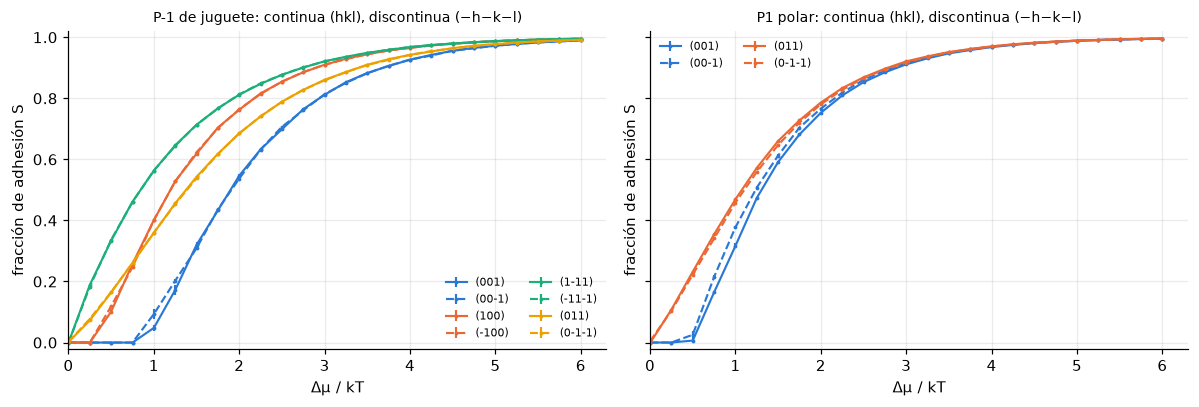

nivel S                     0.1    0.5        0.9
cristal par                                      
P-1     (001) / (00-1)   -0.081  0.006 -7.377e-04
        (011) / (0-1-1)  -0.034  0.008  1.119e-03
        (1-11) / (-11-1)  0.032  0.001 -2.645e-03
        (100) / (-100)   -0.073  0.001 -6.971e-04
P1      (001) / (00-1)   -0.076 -0.054 -1.725e-02
        (011) / (0-1-1)   0.033  0.027  1.049e-02

In [12]:
x1 = np.array([0.21, 0.13, 0.32])          # centro de la GU independiente (fraccionario)
identidad, inversion = (np.eye(3), np.zeros(3)), (-np.eye(3), np.zeros(3))
enlaces = [{"from": 0, "to_frac": (-x1).tolist(), "energy": 4.5, "label": "dímero"},
           {"from": 0, "to_frac": (x1 + [1, 0, 0]).tolist(), "energy": 2.4},
           {"from": 0, "to_frac": (x1 + [0, 1, 0]).tolist(), "energy": 1.8},
           {"from": 0, "to_frac": (x1 + [0, 0, 1]).tolist(), "energy": 0.9},
           {"from": 0, "to_frac": (-x1 + [1, 0, 0]).tolist(), "energy": 1.35},
           {"from": 0, "to_frac": (-x1 + [0, 1, 1]).tolist(), "energy": 0.75}]
g_p1bar = BasisGraph.from_centers(cell_j, [x1], enlaces, [identidad, inversion], units="kT", name="P-1 de juguete")
display(g_p1bar.bond_table())
PARES = {"P-1": (g_p1bar, [("(001)", "(00-1)"), ("(100)", "(-100)"), ("(1-11)", "(-11-1)"), ("(011)", "(0-1-1)")]),
         "P1": (g_p1, [("(001)", "(00-1)"), ("(011)", "(0-1-1)")])}
tareas = []
for grupo, (g, pares) in PARES.items():
    caras = [c for p in pares for c in p]
    tareas += monty.sticking_grid({"graph": g.to_dict(), "size": (30, 30), "n_equil": 30_000,
                                   "n_sample": 100_000, "keep_map": False, "grupo": grupo,
                                   "allow_enclosed": True},
                                  caras, delta_mu=np.round(np.arange(0, 6.01, 0.25), 3), seeds=(1, 2, 3))
df_op, _ = barrido("caras_opuestas_monty", tareas)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
filas = []
for ax, (grupo, (g, pares)) in zip(axes, PARES.items()):
    sub = df_op[df_op["grupo"] == grupo]
    on = monty.onset_table(sub).set_index("hkl")
    for i, (a, b) in enumerate(pares):
        monty.plot_sticking(sub, ax=ax, faces=[a], color=COLORES[i], ls="-")
        monty.plot_sticking(sub, ax=ax, faces=[b], color=COLORES[i], ls="--")
        for lv in (0.1, 0.5, 0.9):
            va, vb = on.loc[a, f"delta_mu@S={lv:g}"], on.loc[b, f"delta_mu@S={lv:g}"]
            filas.append({"cristal": grupo, "par": f"{a} / {b}", "nivel S": lv, "Δμ(hkl)": va,
                          "Δμ(−h−k−l)": vb, "diferencia relativa": (vb - va) / va})
    ax.set_title(f"{g.name}: continua (hkl), discontinua (−h−k−l)", fontsize=9)
    ax.legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout()
guardar(fig, "caras_opuestas")
plt.show()
tab_op = pd.DataFrame(filas)
tab_op.pivot_table(index=["cristal", "par"], columns="nivel S", values="diferencia relativa")

## 3. Parte B: las tres grasas

### 3.1 Referencia: Figs. 2–4 de MONTY digitalizadas

`scripts/digitalizar_monty.py` calibra cada figura por píxeles (marco de los ejes y
etiquetas de los ticks) y lista dónde cruzan las curvas las filas de S = 0.1, 0.5 y 0.9.
Los cruces se asignaron a mano a cada grupo de curvas en
`data/monty2004/referencia_figuras.csv`. En la figura de control, los círculos rojos son
los valores de la tabla sobre las figuras originales. Los grupos de la Fig. 4, con las
curvas muy juntas y las etiquetas encima, tienen confianza «media».

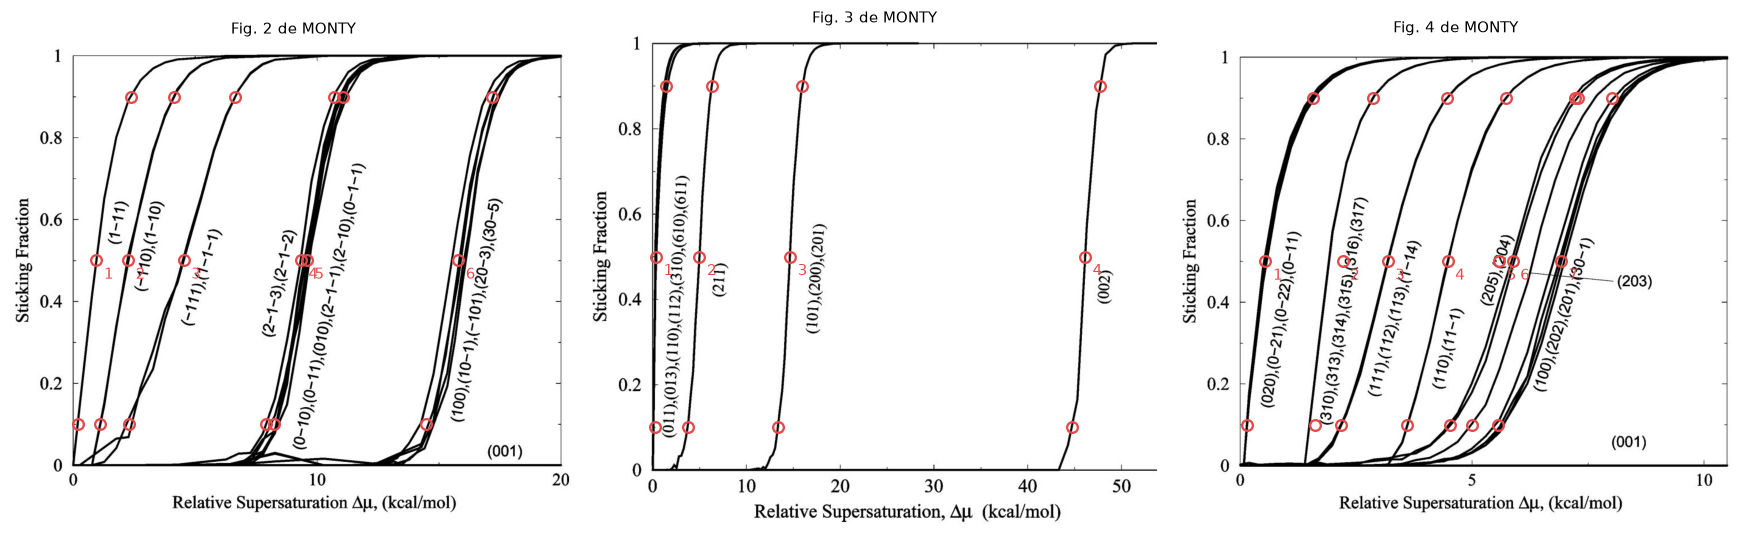

,grasa,figura,T_K,grupo,caras,tipo,dmu_texto,dmu_S01,dmu_S05,dmu_S09,dmu_err,confianza
0,beta_16_16_16,2,313,1,(1-11),superior no conexa,0.0,0.19,0.95,2.36,0.10,alta
1,beta_16_16_16,2,313,2,(-110) (1-10),superior no conexa,0.0,1.11,2.25,4.14,0.10,alta
2,beta_16_16_16,2,313,3,(-111) (1-1-1),superior no conexa,0.0,2.30,4.53,6.65,0.15,alta
3,beta_16_16_16,2,313,4,(2-1-3) (2-1-2),superior no conexa (se rompe en tejado),7.0,7.92,9.34,10.72,0.15,alta
4,beta_16_16_16,2,313,5,(0-10) (0-11) (010) (2-1-1) (2-10) (0-1-1),superior,7.0,8.25,9.59,11.08,0.20,alta
5,beta_16_16_16,2,313,6,(100) (10-1) (-101) (20-3) (30-5),lateral,13.0,14.50,15.80,17.20,0.30,alta
6,beta_16_16_16,2,313,7,(001),basal,60.0,NaN,NaN,NaN,5.00,texto
7,betap_10_12_10,3,300,1,(011) (013) (110) (112) (310) (610) (611),superior,0.0,0.20,0.35,1.43,0.20,media
8,betap_10_12_10,3,300,2,(211),superior,2.0,3.73,4.97,6.27,0.15,alta
9,betap_10_12_10,3,300,3,(101) (200) (201),lateral,12.0,13.34,14.64,15.94,0.20,alta


In [13]:
import digitalizar_monty as dig

REF = monty.load_reference()
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, (nfig, (nombre, top, bot, x0, sx)) in zip(axes, dig.CALIBRACION.items()):
    ax.imshow(dig.leer_imagen(nombre), cmap="gray")
    for _, r in REF[REF["figura"] == nfig].iterrows():
        for S, col in ((0.1, "dmu_S01"), (0.5, "dmu_S05"), (0.9, "dmu_S09")):
            if np.isfinite(r[col]):
                xp, yp = x0 + r[col] * sx, bot - S * (bot - top)
                ax.plot(xp, yp, "o", ms=7, mfc="none", mec="#e34948", mew=1.5)
                if S == 0.5:
                    ax.annotate(str(r["grupo"]), (xp, yp), color="#e34948", fontsize=10,
                                xytext=(5, -12), textcoords="offset points")
    ax.set_title(f"Fig. {nfig} de MONTY", fontsize=10)
    ax.axis("off")
fig.tight_layout()
guardar(fig, "referencia_digitalizada")
plt.show()
REF

Los cocientes que da el texto (§3.2.2) usan como medida el arranque de las curvas:
- lateral : basal = 13 : 60 en β-16.16.16 y 12 : 43 en β′-10.12.10 (cristales más
  laminares en el primero);
- superior : lateral = 7 : 13 y 2 : 12 (agujas mucho más alargadas en β′-10.12.10).

### 3.2 Estado de los datos y comparación

Los grafos cristalinos de las grasas (energías de par en kcal/mol, calculadas por los
autores con CVFF en Cerius²) no están en el artículo de MONTY sino en sus refs. 16 y 17
(Hollander et al., *J. Phys. Chem. B* **103**, 8301 (1999) y **107**, 5680 (2003)).
Cuando estén transcritos en `data/monty2004/<grasa>.json` (formato en
`data/monty2004/README.md`) y barridos con `scripts/run_monty.py`, esta sección:
1. comprueba el grafo: Z, energía de red, longitudes de enlace y tabla de E_att por cara;
2. dibuja la morfología de energía de unión (fila superior de la Fig. 1);
3. dibuja las curvas S(Δμ) con la referencia encima y compara grupo a grupo
   (`monty.compare_with_reference`, criterio ±20 % o ±1 kcal/mol, y orden de los
   grupos con `monty.order_agreement`).

In [14]:
from kmc3d import analysis as an

GRASAS = {"beta_16_16_16": "β-16.16.16 (Fig. 2)", "betap_10_12_10": "β′-10.12.10 (Fig. 3)",
          "betap_16_16_14": "β′-16.16.14 (Fig. 4)"}
estado = []
for clave, nombre in GRASAS.items():
    fj = monty.DATA_DIR / f"{clave}.json"
    fb = OUT / "barridos" / f"{clave}.csv"
    estado.append({"grasa": nombre, "grafo": fj.exists(), "barrido": fb.exists(),
                   "puntos del barrido": len(pd.read_csv(fb)) if fb.exists() else 0})
estado = pd.DataFrame(estado)
display(estado)
if not estado["grafo"].any():
    print("Pendiente: faltan los grafos de las grasas (refs. 16 y 17 de MONTY). "
          "La parte B se completa al transcribirlos.")

,grasa,grafo,barrido,puntos del barrido
0,β-16.16.16 (Fig. 2),False,False,0
1,β′-10.12.10 (Fig. 3),False,False,0
2,β′-16.16.14 (Fig. 4),False,False,0


Pendiente: faltan los grafos de las grasas (refs. 16 y 17 de MONTY). La parte B se completa al transcribirlos.


In [15]:
def revisar_grafo(clave):
    # Comprobaciones del grafo transcrito y morfología de energía de unión (Fig. 1)
    g, meta = monty.load_graph_file(monty.DATA_DIR / f"{clave}.json")
    caras = [monty._as_hkl(f) for f in meta.get("faces", [])]
    print(f"{GRASAS[clave]}: {g}; E_cr = {g.lattice_energy:.2f} {g.units}; "
          f"fuente: {meta.get('fuente', '¿?')}")
    display(g.bond_table())
    tabla = g.face_table(caras)
    display(tabla)
    # R ∝ |E_att|, con las dos caras de cada par ±(hkl) (estos grupos no siempre tienen inversión)
    rates = {}
    for f, ea in zip(caras, tabla["E_att"]):
        rates[f] = abs(ea)
    rates.update({tuple(-x for x in f): v for f, v in list(rates.items()) if tuple(-x for x in f) not in rates})
    caras_w, _ = an.wulff_faces(rates, g.cell, centrosymmetric=False)
    fig, ax = plt.subplots(figsize=(4.5, 4.5), subplot_kw={"projection": "3d"})
    render.plot_polyhedron(caras_w, ax=ax, cell=g.cell, title=f"E_att: {GRASAS[clave]}")
    guardar(fig, f"{clave}_energia_union")
    plt.show()


def comparar(clave):
    # Curvas S(Δμ) simuladas con la referencia de MONTY encima y tabla por grupos
    df = pd.read_csv(OUT / "barridos" / f"{clave}.csv")
    ref = REF[REF["grasa"] == clave]
    fig, ax = plt.subplots(figsize=(7, 4.8))
    for i, (_, r) in enumerate(ref.iterrows()):
        caras = [c for c in r["caras"].split() if c in set(df["hkl"])]
        color = COLORES[i % len(COLORES)]
        if caras:
            monty.plot_sticking(df, ax=ax, x="delta_mu_kcal", faces=caras, color=color, label=False)
        for S, col in ((0.1, "dmu_S01"), (0.5, "dmu_S05"), (0.9, "dmu_S09")):
            if np.isfinite(r[col]):
                ax.plot(r[col], S, "o", ms=8, mfc="none", mec=color, mew=1.8)
    ax.set_title(f"{GRASAS[clave]}: kmc3d (líneas) y MONTY (círculos)", fontsize=10)
    fig.tight_layout()
    guardar(fig, f"{clave}_S_vs_dmu")
    plt.show()
    comp = monty.compare_with_reference(df, REF, clave)
    display(comp)
    print(f"Pares de grupos en el mismo orden que MONTY: {monty.order_agreement(comp):.0%}")
    return comp


comparaciones = {}
for clave, fila in zip(GRASAS, estado.itertuples()):
    if fila.grafo:
        revisar_grafo(clave)
    if fila.barrido:
        comparaciones[clave] = comparar(clave)

## 4. Conclusiones y pendientes

**Parte A: el motor de superficie reproduce el protocolo de MONTY.**

1. **Tasas.** `MontyRates(λ1, λ2)` coincide exactamente con `SplitRates(1 − λ2, λ1)` en los
   2187 códigos de β-hematina y cumple el balance detallado al error de redondeo.
2. **Equilibrio.** A Δμ = 0, S → 0: como 1/N en la cara lisa (001) (rms de 8·10⁻⁴ a
   4·10⁻⁵ entre 10⁴ y 3·10⁵ eventos) y como 1/√N en las rugosas.
3. **Simetría partícula-hueco** (la prueba más fina). Con las reglas de MONTY, crecer
   (hkl) a +Δμ y disolver (−h−k−l) a −Δμ dan la misma velocidad.
   - En Kossel, coinciden dentro del 2 % cerca del umbral de (001) (|z| < 1) y del
     0.2 % en el resto. Un punto, (111) a Δμ = 3, sale a |z| = 3.7 con una diferencia
     del 0.2 %. Con 6 semillas, z sigue una t de Student con unos 10 grados de
     libertad, y en 20 puntos la probabilidad de un |t| ≥ 3.7 es de un 8 %.
   - En el P1 polar, |z| ≤ 1 en los 8 puntos.
   - Si los huecos cerrados no se llenan (la regla de `KMC3D`), la simetría se rompe
     en el P1 (hasta z = −12), y S baja hasta 0.14. En Kossel casi no se nota.
   - Gilmer no es simétrico, como se espera.

   Esto comprueba a la vez las tasas, las reglas STS, los códigos de vecindad, el
   contorno periódico y la caja que crece por arriba y por abajo.
4. **Kossel.**
   - (001) tiene un umbral que sube con φ: Δμ(S = 0.1) = 0.24, 0.65, 1.20 y 1.85 kT
     para φ = 2–5.
   - (011) y (111) crecen desde Δμ = 0, como dice Hartman-Perdok.
   - Las caras rugosas quedan cerca del límite de kinks 1 − e^(−Δμ), que da S = ½ en
     ln 2 = 0.69 kT. La (111), cara K, llega a S = ½ en 0.74–0.75 kT para todos los φ.
     La (011), cara S, se aleja del límite al subir φ (0.78 → 0.94 kT): con menos
     kinks, una parte mayor de las uniones son de adátomos que vuelven a irse.
5. **Energía de borde.** El valor exacto de Onsager queda entre las estimaciones
   mononuclear y de birth-and-spread para φ = 3, 4 y 5, y se acerca a la mononuclear
   al subir φ, cuando la nucleación es más rara. Con φ = 5, la mononuclear da 2.30 kT
   frente a 2.34 de Onsager.
6. **Superficie frente a cristal finito.** Con una semilla de L = 20, el cristal de
   `KMC3D` crece entre un 3 % y un 18 % más despacio que el slab. Es un efecto de tamaño
   finito: con L = 48 llega al 99 % (Gilmer) y al 98 % (simétricas) del valor del slab.
7. **Supercelda.** Δμ(S = ½) coincide con base 1 y con base 2 dentro de un 1 %: Kossel
   (001), 1.932 frente a 1.953; β-hematina (100), 1.279 frente a 1.271.
8. **Caras opuestas.**
   - En el P-1 de juguete coinciden: diferencia ≤ 0.8 % en S = ½.
   - En el P1 polar, (001) y (00-1) se separan un 5 % en S = ½, pero no en el umbral.
     Con enlaces de par, las caras opuestas rompen los mismos enlaces.

   La prueba de MONTY comprueba el código (base > 1, celda de capa) más que la física.

**Regla de los huecos cerrados (decisión del autor, 2026-11-24).** El slab sigue a MONTY:
`SlabKMC` y `monty.sticking_point` usan `allow_enclosed=True` por defecto. `KMC3D`
(β-hematina) no cambia: allí sigue `False` (D4). En Kossel la diferencia es
despreciable; en el P1 polar cambia S hasta 0.14.

**Supuesto a vigilar.** Si una estructura tiene GU que no son equivalentes por simetría
(Z′ > 1) y con energías totales distintas, Δμ = 0 con E_cr = Σφ/Z deja de ser la
coexistencia a T > 0. Un primer control P1, con 14.1 y 5.5 kT por subred, daba
S(Δμ = 0) ≈ −0.03.

**Parte B (pendiente).** La referencia digitalizada está lista (§3.1). Faltan los grafos
de las grasas (refs. 16 y 17 de MONTY). Para completarla:
1. transcribirlos a `data/monty2004/<grasa>.json`;
2. barrer con `scripts/run_monty.py`;
3. volver a ejecutar el §3.2.

In [16]:
print(f"Tiempo total del notebook: {(time.perf_counter() - T0_NOTEBOOK) / 60:.1f} min")

Tiempo total del notebook: 0.1 min
